# Encoder Ablation: Donut vs. Pix2Struct
### IE 643 Course Project — Team NeuroFusion (Jaydip 22b4221, Disham 22b4211)

This notebook is **standalone** — it does not depend on the earlier T5-vs-BART notebook's session
or files. It holds the decoder architecture **fixed (T5)** and swaps the **vision encoder** between:

- **Pix2Struct** — document/screenshot-pretrained, variable-resolution patching
- **Donut** — a different document-pretrained encoder (Swin Transformer backbone, fixed resolution)

Both are document-pretrained (as your project requires, vs. a natural-image encoder like CLIP), so
this isolates *which* document encoder reads chart values better — direct evidence for the
"encoder selection and justification" part of your deliverables.

Training is **weak-supervision only**: targets come from a rule-based miner that extracts
`(category, value)` pairs straight from question/answer text — the ground-truth table is loaded
only afterward, for evaluation.

**What gets saved** (under `/kaggle/working/experiments_encoder_ablation/`):
- `pix2struct_t5/` and `donut_t5/` — each with its own loss history, loss curve, per-epoch sample
  generations, and trainable weights
- `encoder_ablation_comparison.csv` / `.png` — side-by-side comparison
- `experiment_report.json` — one file to quote numbers from in your report
- An inference cell: give it any new chart image, generate a table with either encoder

**Compute note:** Donut's default resolution is heavier per-image than Pix2Struct's patch budget
here, so it's explicitly capped down (`size={"height": 640, "width": 480}`) — a documented,
deliberate simplification for your time/GPU budget, not a silent one.

## Step 0 — Install / import / config

In [1]:
# Kaggle images sometimes ship an older transformers version without full Pix2Struct/Donut support.
!pip install -q -U "transformers>=4.38" sentencepiece

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
gradio 6.26.0 requires pillow<13.0,>=8.0, but you have pillow 13.0.0 which is incompatible.


In [20]:
import os, re, json, glob, random, time
from collections import defaultdict

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from transformers import (
    Pix2StructForConditionalGeneration, Pix2StructProcessor,
    VisionEncoderDecoderModel, DonutProcessor,
    T5ForConditionalGeneration, AutoTokenizer,
)
from transformers.modeling_outputs import BaseModelOutput

SEED = 42
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", DEVICE)

CONFIG = {
    # ---- data ----
    "n_train": 6400,
    "n_val":   750,
    "n_test":  1600,
    # ---- encoders (both document-pretrained) ----
    "pix2struct_name": "google/pix2struct-base",
    "max_patches": 512,
    "donut_name": "naver-clova-ix/donut-base",
    "donut_size": {"height": 640, "width": 480},   # capped down for compute budget
    # ---- decoder (held fixed across both arms) ----
    "t5_name": "t5-small",
    "max_target_len": 256,
    # ---- training ----
    "batch_size_pix2struct": 4,
    "batch_size_donut": 2,     # Donut is heavier per-image at this resolution
    "epochs": 30,
    "lr": 3e-4,
    "weight_decay": 0.01,
    "grad_clip": 1.0,
    "num_workers": 2,
    # ---- output ----
    "out_dir": "/kaggle/working/experiments_encoder_ablation",
}
os.makedirs(CONFIG["out_dir"], exist_ok=True)
print(json.dumps(CONFIG, indent=2))

Device: cuda
{
  "n_train": 6400,
  "n_val": 750,
  "n_test": 1600,
  "pix2struct_name": "google/pix2struct-base",
  "max_patches": 512,
  "donut_name": "naver-clova-ix/donut-base",
  "donut_size": {
    "height": 640,
    "width": 480
  },
  "t5_name": "t5-small",
  "max_target_len": 256,
  "batch_size_pix2struct": 4,
  "batch_size_donut": 2,
  "epochs": 30,
  "lr": 0.0003,
  "weight_decay": 0.01,
  "grad_clip": 1.0,
  "num_workers": 2,
  "out_dir": "/kaggle/working/experiments_encoder_ablation"
}


## Step 0b — Inspect your dataset (run this and read the printed output first!)

Searches everything under `/kaggle/input` for ChartQA-style JSON annotations and chart PNGs, and
prints what it finds plus one sample record, so you can confirm (or fix) the key names used in
`load_split()` below.

In [21]:
INPUT_ROOT = "/kaggle/input"

def tree_preview(root, max_entries=60):
    count = 0
    for dirpath, dirnames, filenames in os.walk(root):
        depth = dirpath[len(root):].count(os.sep)
        if depth > 3:
            dirnames[:] = []
            continue
        indent = "  " * depth
        print(f"{indent}{os.path.basename(dirpath) or dirpath}/")
        for f in filenames[:5]:
            print(f"{indent}  {f}")
            count += 1
            if count > max_entries:
                return
        if len(filenames) > 5:
            print(f"{indent}  ... ({len(filenames)} files total)")

print("=== Directory preview under /kaggle/input ===")
tree_preview(INPUT_ROOT)

json_files = glob.glob(f"{INPUT_ROOT}/**/*.json", recursive=True)
print(f"\n=== {len(json_files)} JSON annotation files found, e.g.: ===")
for f in json_files[:10]:
    print(f)

if json_files:
    with open(json_files[0]) as f:
        data = json.load(f)
    print(f"\n=== Sample content of {json_files[0]} ===")
    print(json.dumps(data[:2] if isinstance(data, list) else data, indent=2)[:1200])

png_files = glob.glob(f"{INPUT_ROOT}/**/*.png", recursive=True)
print(f"\n=== {len(png_files)} PNG chart images found ===")

csv_files = glob.glob(f"{INPUT_ROOT}/**/*.csv", recursive=True)
print(f"=== {len(csv_files)} table CSV files found ===")

=== Directory preview under /kaggle/input ===
input/
  datasets/
    harshk1111/
      chartqa-dataset/

=== 6 JSON annotation files found, e.g.: ===
/kaggle/input/datasets/harshk1111/chartqa-dataset/ChartQA-Dataset/test/test_augmented.json
/kaggle/input/datasets/harshk1111/chartqa-dataset/ChartQA-Dataset/test/test_human.json
/kaggle/input/datasets/harshk1111/chartqa-dataset/ChartQA-Dataset/train/train_augmented.json
/kaggle/input/datasets/harshk1111/chartqa-dataset/ChartQA-Dataset/train/train_human.json
/kaggle/input/datasets/harshk1111/chartqa-dataset/ChartQA-Dataset/val/val_augmented.json
/kaggle/input/datasets/harshk1111/chartqa-dataset/ChartQA-Dataset/val/val_human.json

=== Sample content of /kaggle/input/datasets/harshk1111/chartqa-dataset/ChartQA-Dataset/test/test_augmented.json ===
[
  {
    "imgname": "multi_col_803.png",
    "query": "How many stores did Saint Laurent operate in Western Europe in 2020?",
    "label": "47"
  },
  {
    "imgname": "multi_col_20436.png",
    "q

In [22]:
# Edit these if Step 0b's printed sample shows different key names.
KEY_ALIASES = {
    "image": ["imgname", "image_index", "image", "img_name", "filename"],
    "question": ["query", "question", "Question"],
    "answer": ["label", "answer", "Answer"],
}

def first_present(d, aliases):
    for k in aliases:
        if k in d:
            return d[k]
    return None

## Step 0c — Build a flat index and subsample

In [23]:
def find_split_jsons():
    found = {"train": [], "val": [], "test": []}
    for jf in json_files:
        name = os.path.basename(jf).lower()
        split = None
        for cand in ["train", "val", "test"]:
            if cand in jf.lower():
                split = cand
                break
        if split is None:
            continue
        source = "human" if "human" in name else ("augmented" if ("augment" in name or "machine" in name) else "unknown")
        found[split].append((jf, source))
    return found

SPLIT_JSONS = find_split_jsons()
for k, v in SPLIT_JSONS.items():
    print(k, "->", v)

train -> [('/kaggle/input/datasets/harshk1111/chartqa-dataset/ChartQA-Dataset/train/train_augmented.json', 'augmented'), ('/kaggle/input/datasets/harshk1111/chartqa-dataset/ChartQA-Dataset/train/train_human.json', 'human')]
val -> [('/kaggle/input/datasets/harshk1111/chartqa-dataset/ChartQA-Dataset/val/val_augmented.json', 'augmented'), ('/kaggle/input/datasets/harshk1111/chartqa-dataset/ChartQA-Dataset/val/val_human.json', 'human')]
test -> [('/kaggle/input/datasets/harshk1111/chartqa-dataset/ChartQA-Dataset/test/test_augmented.json', 'augmented'), ('/kaggle/input/datasets/harshk1111/chartqa-dataset/ChartQA-Dataset/test/test_human.json', 'human')]


In [24]:
def guess_image_dir(json_path):
    base = os.path.dirname(json_path)
    candidates = [os.path.join(base, "png"), base, os.path.join(os.path.dirname(base), "png")]
    for c in candidates:
        if os.path.isdir(c) and len(glob.glob(os.path.join(c, "*.png"))) > 0:
            return c
    parent = os.path.dirname(base)
    pngs = glob.glob(os.path.join(parent, "**", "*.png"), recursive=True)
    return os.path.dirname(pngs[0]) if pngs else base

def guess_table_dir(json_path):
    base = os.path.dirname(json_path)
    for c in [os.path.join(base, "tables"), os.path.join(os.path.dirname(base), "tables")]:
        if os.path.isdir(c):
            return c
    return None

def load_split(split):
    rows = []
    for json_path, source in SPLIT_JSONS.get(split, []):
        img_dir = guess_image_dir(json_path)
        tbl_dir = guess_table_dir(json_path)
        with open(json_path) as f:
            records = json.load(f)
        for r in records:
            img_name = first_present(r, KEY_ALIASES["image"])
            q = first_present(r, KEY_ALIASES["question"])
            a = first_present(r, KEY_ALIASES["answer"])
            if img_name is None or q is None or a is None:
                continue
            img_path = os.path.join(img_dir, img_name)
            tbl_path = None
            if tbl_dir is not None:
                stem = os.path.splitext(img_name)[0]
                cand = os.path.join(tbl_dir, stem + ".csv")
                if os.path.isfile(cand):
                    tbl_path = cand
            rows.append({"split": split, "source": source, "image_path": img_path,
                         "table_path": tbl_path, "question": str(q), "answer": str(a)})
    df = pd.DataFrame(rows)
    df = df[df["image_path"].apply(os.path.isfile)].reset_index(drop=True)
    return df

df_train_full = load_split("train")
df_val_full   = load_split("val")
df_test_full  = load_split("test")
print("Full sizes -> train:", len(df_train_full), " val:", len(df_val_full), " test:", len(df_test_full))

Full sizes -> train: 28297  val: 1916  test: 2500


In [25]:
def subsample(df, n, seed=SEED):
    if len(df) <= n:
        return df.reset_index(drop=True)
    return df.groupby("source", group_keys=False).apply(
        lambda g: g.sample(frac=min(1.0, n / len(df)), random_state=seed)
    ).sample(n=min(n, len(df)), random_state=seed).reset_index(drop=True)

df_train = subsample(df_train_full, CONFIG["n_train"])
df_val   = subsample(df_val_full,   CONFIG["n_val"])
df_test  = subsample(df_test_full,  CONFIG["n_test"])
print("Subsampled sizes -> train:", len(df_train), " val:", len(df_val), " test:", len(df_test))

Subsampled sizes -> train: 6400  val: 750  test: 1600


/tmp/ipykernel_49/2184524279.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return df.groupby("source", group_keys=False).apply(
/tmp/ipykernel_49/2184524279.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future version of pandas the grouping columns will be excluded from the operation. Either pass `include_groups=False` to exclude the groupings or explicitly select the grouping columns after groupby to silence this warning.
  return df.groupby("source", group_keys=False).apply(
/tmp/ipykernel_49/2184524279.py:4: FutureWarning: DataFrameGroupBy.apply operated on the grouping columns. This behavior is deprecated, and in a future 

## Step 1 — Weak-supervision pseudo-table mining

Extracts `(category, value)` pairs purely from question/answer text (never from the table file),
merged per chart into a pseudo-table — the only thing the decoder is ever trained to reproduce.

In [26]:
QUESTION_PATTERNS = [
    re.compile(r"what is the value of (.+?) in .+\?", re.I),
    re.compile(r"what is the value of (.+?)\?", re.I),
    re.compile(r"what is (.+?) in .+\?", re.I),
    re.compile(r"^(.+?) value\?", re.I),
]

def clean_num(s):
    s = s.strip().replace(",", "").replace("$", "")
    if s.endswith("%"):
        s = s[:-1]
    try:
        return float(s)
    except ValueError:
        return None

def mine_pair(question, answer):
    val = clean_num(answer)
    if val is None:
        return None
    for pat in QUESTION_PATTERNS:
        m = pat.match(question.strip())
        if m:
            category = m.group(1).strip().strip('"').strip("'")
            if 0 < len(category) <= 40:
                return category, val
    return None

def build_pseudo_tables(df):
    pseudo = defaultdict(dict)
    mined_flags = []
    for _, row in df.iterrows():
        mined = mine_pair(row["question"], row["answer"])
        if mined is not None:
            cat, val = mined
            pseudo[row["image_path"]][cat] = val
            mined_flags.append(True)
        else:
            mined_flags.append(False)
    return dict(pseudo), mined_flags

pseudo_train, mined_flags_train = build_pseudo_tables(df_train)
df_train["mined"] = mined_flags_train

coverage = sum(mined_flags_train) / max(1, len(mined_flags_train))
print(f"Mined {sum(mined_flags_train)} / {len(df_train)} training QA pairs ({coverage:.1%})")

usable_charts = {k for k, v in pseudo_train.items() if len(v) > 0}
df_train_usable = df_train[df_train["image_path"].isin(usable_charts)].drop_duplicates("image_path").reset_index(drop=True)
print("Unique usable training charts:", len(df_train_usable))

Mined 223 / 6400 training QA pairs (3.5%)
Unique usable training charts: 219


In [27]:
def linearize_table(table_dict):
    items = sorted(table_dict.items())
    return " ; ".join(f"{k} = {v:g}" for k, v in items)

def delinearize_table(text):
    out = {}
    for part in text.split(";"):
        if "=" not in part:
            continue
        k, v = part.split("=", 1)
        k = k.strip()
        v = clean_num(v.strip())
        if k and v is not None:
            out[k] = v
    return out

df_train_usable["target_text"] = df_train_usable["image_path"].map(lambda p: linearize_table(pseudo_train[p]))

df_train_usable = df_train_usable.sample(frac=1.0, random_state=SEED).reset_index(drop=True)
n_val_internal = max(20, int(0.08 * len(df_train_usable)))
df_val_internal = df_train_usable.iloc[:n_val_internal].reset_index(drop=True)
df_train_final  = df_train_usable.iloc[n_val_internal:].reset_index(drop=True)
print("Train (gradient updates):", len(df_train_final), " Internal val:", len(df_val_internal))
print(df_train_final[["image_path", "target_text"]].head(3).to_string())

Train (gradient updates): 199  Internal val: 20
                                                                                                                                               image_path                                      target_text
0                                                           /kaggle/input/datasets/harshk1111/chartqa-dataset/ChartQA-Dataset/train/png/two_col_43477.png            the smallest value represented = 0.37
1                                                           /kaggle/input/datasets/harshk1111/chartqa-dataset/ChartQA-Dataset/train/png/two_col_21146.png  the price of oil expected to increase to = 64.5
2  /kaggle/input/datasets/harshk1111/chartqa-dataset/ChartQA-Dataset/train/png/OECD_FDI_INCOME_RECEIPTS_BY_PARTNER_COUNTRY_CHE_CHL_EST_ITA_NZL_000006.png    the difference = 18.4 ; the purple bar = 22.8


## Step 2 — Load both encoders correctly

Both are loaded from their **full** checkpoint first, then sliced down to just the vision tower.
Loading a bare `*VisionModel` class directly against a checkpoint saved from the full
conditional-generation model causes a silent key-prefix mismatch (every weight falls back to
random init, with no hard error) — loading the full model first and keeping `.encoder` avoids that.

In [28]:
# ---- Pix2Struct ----
_full_p2s = Pix2StructForConditionalGeneration.from_pretrained(CONFIG["pix2struct_name"])
pix2struct_vision_encoder = _full_p2s.encoder
del _full_p2s.decoder
for p in pix2struct_vision_encoder.parameters():
    p.requires_grad = False
pix2struct_vision_encoder.eval().to(DEVICE)

processor = Pix2StructProcessor.from_pretrained(CONFIG["pix2struct_name"])
PIX2STRUCT_HIDDEN = pix2struct_vision_encoder.config.hidden_size
print("Pix2Struct encoder ready, hidden size:", PIX2STRUCT_HIDDEN)

Loading weights:   0%|          | 0/285 [00:00<?, ?it/s]

Pix2Struct encoder ready, hidden size: 768


In [29]:
# ---- Donut ----
_full_donut = VisionEncoderDecoderModel.from_pretrained(CONFIG["donut_name"])
donut_vision_encoder = _full_donut.encoder
del _full_donut.decoder
for p in donut_vision_encoder.parameters():
    p.requires_grad = False
donut_vision_encoder.eval().to(DEVICE)

donut_processor = DonutProcessor.from_pretrained(CONFIG["donut_name"])
donut_image_processor = donut_processor.image_processor
donut_image_processor.size = CONFIG["donut_size"]

with torch.no_grad():
    dummy = torch.zeros(1, 3, CONFIG["donut_size"]["height"], CONFIG["donut_size"]["width"]).to(DEVICE)
    dummy_out = donut_vision_encoder(pixel_values=dummy).last_hidden_state
DONUT_HIDDEN = dummy_out.shape[-1]
print("Donut encoder ready. Output shape (batch, seq_len, hidden):", dummy_out.shape)

try:
    w = donut_vision_encoder.encoder.layers[0].blocks[0].attention.self.query.weight
    print("Sample weight stats (mean, std):", w.mean().item(), w.std().item(),
          "-- should look like trained values, not a narrow fresh-init range")
except AttributeError:
    print("(Could not introspect internal weight path; does not affect correctness.)")

Loading weights:   0%|          | 0/484 [00:00<?, ?it/s]

Donut encoder ready. Output shape (batch, seq_len, hidden): torch.Size([1, 300, 1024])
Sample weight stats (mean, std): -0.00022252871713135391 0.08201957494020462 -- should look like trained values, not a narrow fresh-init range


## Step 3 — Model, dataset and generic training/eval utilities (encoder-agnostic)

In [30]:
class ChartTableGeneratorV2(nn.Module):
    """Swappable ENCODER ('pix2struct' or 'donut'), decoder (T5) held fixed."""
    def __init__(self, encoder_type, decoder_name=None):
        super().__init__()
        assert encoder_type in ("pix2struct", "donut")
        self.encoder_type = encoder_type
        decoder_name = decoder_name or CONFIG["t5_name"]

        if encoder_type == "pix2struct":
            self.vision_encoder = pix2struct_vision_encoder
            enc_hidden = PIX2STRUCT_HIDDEN
        else:
            self.vision_encoder = donut_vision_encoder
            enc_hidden = DONUT_HIDDEN

        self.lm = T5ForConditionalGeneration.from_pretrained(decoder_name)
        dec_hidden = self.lm.config.d_model
        self.proj = nn.Linear(enc_hidden, dec_hidden)
        self.ln = nn.LayerNorm(dec_hidden)

    def encode(self, batch):
        if self.encoder_type == "pix2struct":
            with torch.no_grad():
                enc_out = self.vision_encoder(
                    flattened_patches=batch["flattened_patches"], attention_mask=batch["attention_mask"]
                ).last_hidden_state
            enc_mask = batch["attention_mask"]
        else:
            with torch.no_grad():
                enc_out = self.vision_encoder(pixel_values=batch["pixel_values"]).last_hidden_state
            enc_mask = torch.ones(enc_out.shape[:2], dtype=torch.long, device=enc_out.device)
        enc_out = self.ln(self.proj(enc_out))
        return enc_out, enc_mask

    def forward(self, labels=None, **batch):
        enc_hidden, enc_mask = self.encode(batch)
        encoder_outputs = BaseModelOutput(last_hidden_state=enc_hidden)
        return self.lm(encoder_outputs=encoder_outputs, attention_mask=enc_mask, labels=labels)

    @torch.no_grad()
    def generate(self, max_new_tokens=256, num_beams=2, **batch):
        enc_hidden, enc_mask = self.encode(batch)
        encoder_outputs = BaseModelOutput(last_hidden_state=enc_hidden)
        return self.lm.generate(encoder_outputs=encoder_outputs, attention_mask=enc_mask,
                                 max_new_tokens=max_new_tokens, num_beams=num_beams)

def count_params(model):
    trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
    frozen = sum(p.numel() for p in model.parameters() if not p.requires_grad)
    return trainable, frozen

In [31]:
class ChartTableDatasetV2(Dataset):
    def __init__(self, df, tokenizer, max_target_len, encoder_type):
        self.df = df.reset_index(drop=True)
        self.tokenizer = tokenizer
        self.max_target_len = max_target_len
        self.encoder_type = encoder_type

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        image = Image.open(row["image_path"]).convert("RGB")

        if self.encoder_type == "pix2struct":
            enc = processor(images=image, return_tensors="pt", max_patches=CONFIG["max_patches"])
            img_inputs = {
                "flattened_patches": enc["flattened_patches"].squeeze(0),
                "attention_mask": enc["attention_mask"].squeeze(0),
            }
        else:
            enc = donut_image_processor(image, return_tensors="pt")
            img_inputs = {"pixel_values": enc["pixel_values"].squeeze(0)}

        target = self.tokenizer(
            row["target_text"], return_tensors="pt",
            truncation=True, max_length=self.max_target_len, padding="max_length",
        )
        labels = target["input_ids"].squeeze(0)
        labels[labels == self.tokenizer.pad_token_id] = -100
        return {**img_inputs, "labels": labels}

def collate_fn_v2(batch):
    keys = batch[0].keys()
    return {k: torch.stack([b[k] for b in batch]) for k in keys}

def encode_single_image(image, encoder_type):
    if encoder_type == "pix2struct":
        enc = processor(images=image, return_tensors="pt", max_patches=CONFIG["max_patches"])
        return {"flattened_patches": enc["flattened_patches"], "attention_mask": enc["attention_mask"]}
    else:
        enc = donut_image_processor(image, return_tensors="pt")
        return {"pixel_values": enc["pixel_values"]}

In [32]:
def train_model_v2(model, tokenizer, df_train_final, df_val_internal, tag, encoder_type, batch_size):
    exp_dir = os.path.join(CONFIG["out_dir"], tag)
    os.makedirs(exp_dir, exist_ok=True)

    train_ds = ChartTableDatasetV2(df_train_final, tokenizer, CONFIG["max_target_len"], encoder_type)
    val_ds   = ChartTableDatasetV2(df_val_internal, tokenizer, CONFIG["max_target_len"], encoder_type)
    train_loader = DataLoader(train_ds, batch_size=batch_size, shuffle=True,
                               num_workers=CONFIG["num_workers"], collate_fn=collate_fn_v2)
    val_loader   = DataLoader(val_ds, batch_size=batch_size, shuffle=False,
                               num_workers=CONFIG["num_workers"], collate_fn=collate_fn_v2)

    model.to(DEVICE)
    trainable, frozen = count_params(model)
    print(f"[{tag}] trainable params: {trainable:,}  frozen params: {frozen:,}")

    optim = torch.optim.AdamW([p for p in model.parameters() if p.requires_grad],
                               lr=CONFIG["lr"], weight_decay=CONFIG["weight_decay"])

    history, sample_generations = [], []
    for epoch in range(1, CONFIG["epochs"] + 1):
        model.train()
        t0 = time.time()
        total_loss, n_batches = 0.0, 0
        for batch in train_loader:
            batch = {k: v.to(DEVICE) for k, v in batch.items()}
            optim.zero_grad()
            out = model(**batch)
            out.loss.backward()
            torch.nn.utils.clip_grad_norm_([p for p in model.parameters() if p.requires_grad], CONFIG["grad_clip"])
            optim.step()
            total_loss += out.loss.item(); n_batches += 1
        train_loss = total_loss / max(1, n_batches)

        model.eval()
        val_loss, n_val_batches = 0.0, 0
        with torch.no_grad():
            for batch in val_loader:
                batch = {k: v.to(DEVICE) for k, v in batch.items()}
                val_loss += model(**batch).loss.item(); n_val_batches += 1
        val_loss = val_loss / max(1, n_val_batches)

        dt = time.time() - t0
        print(f"[{tag}] epoch {epoch}/{CONFIG['epochs']}  train_loss={train_loss:.4f}  val_loss={val_loss:.4f}  ({dt:.1f}s)")
        history.append({"epoch": epoch, "train_loss": train_loss, "val_loss": val_loss, "seconds": dt})

        gens = []
        for _, row in df_val_internal.iloc[:2].iterrows():
            image = Image.open(row["image_path"]).convert("RGB")
            inputs = {k: v.to(DEVICE) for k, v in encode_single_image(image, encoder_type).items()}
            out_ids = model.generate(max_new_tokens=CONFIG["max_target_len"], num_beams=2, **inputs)
            text = tokenizer.decode(out_ids[0], skip_special_tokens=True)
            gens.append({"image_path": row["image_path"], "target": row["target_text"], "generated": text})
        sample_generations.append({"epoch": epoch, "samples": gens})

    pd.DataFrame(history).to_csv(os.path.join(exp_dir, "loss_history.csv"), index=False)
    with open(os.path.join(exp_dir, "sample_generations.json"), "w") as f:
        json.dump(sample_generations, f, indent=2)
    torch.save({"proj": model.proj.state_dict(), "ln": model.ln.state_dict(), "lm": model.lm.state_dict()},
               os.path.join(exp_dir, "trainable_weights.pt"))

    hist_df = pd.DataFrame(history)
    plt.figure(figsize=(6, 4))
    plt.plot(hist_df["epoch"], hist_df["train_loss"], marker="o", label="train loss")
    plt.plot(hist_df["epoch"], hist_df["val_loss"], marker="o", label="val loss")
    plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title(f"{tag}: loss vs. epoch")
    plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
    plt.savefig(os.path.join(exp_dir, "loss_curve.png"), dpi=150)
    plt.show()

    return {"tag": tag, "exp_dir": exp_dir, "encoder_type": encoder_type,
            "trainable_params": trainable, "frozen_params": frozen,
            "final_train_loss": history[-1]["train_loss"], "final_val_loss": history[-1]["val_loss"],
            "history": history}

In [33]:
def load_gold_table(table_path):
    if table_path is None or not os.path.isfile(table_path):
        return None
    try:
        gold_df = pd.read_csv(table_path, sep=None, engine="python")
    except Exception:
        return None
    table = {}
    label_col = gold_df.columns[0]
    for _, r in gold_df.iterrows():
        cat = str(r[label_col]).strip()
        for col in gold_df.columns[1:]:
            val = clean_num(str(r[col]))
            if val is not None:
                table[f"{cat}" if len(gold_df.columns) <= 2 else f"{cat} ({col})"] = val
    return table

def cell_accuracy(pred_table, gold_table, mined_categories, tol=0.05):
    def close(a, b):
        if a is None or b is None:
            return False
        return abs(a - b) / max(abs(b), 1e-6) <= tol
    overall, mined, unmined = [], [], []
    for cat, gold_val in gold_table.items():
        ok = close(pred_table.get(cat), gold_val)
        overall.append(ok)
        (mined if cat in mined_categories else unmined).append(ok)
    def rate(lst):
        return (sum(lst) / len(lst)) if lst else None
    return rate(overall), rate(mined), rate(unmined)

def simple_qa_execute(question, pred_table):
    q = question.lower()
    values = list(pred_table.values())
    if not values:
        return None
    if "sum" in q or "total" in q:
        return sum(values)
    if "average" in q or "mean" in q:
        return sum(values) / len(values)
    if "maximum" in q or "highest" in q or "largest" in q:
        return max(values)
    if "minimum" in q or "lowest" in q or "smallest" in q:
        return min(values)
    mined = mine_pair(question, "0")
    return pred_table.get(mined[0]) if mined is not None else None

def evaluate_architecture_v2(model, tokenizer, df_eval, encoder_type, tag=""):
    model.eval()
    rows = []
    for _, row in df_eval.drop_duplicates("image_path").iterrows():
        gold_table = load_gold_table(row["table_path"])
        if not gold_table:
            continue
        image = Image.open(row["image_path"]).convert("RGB")
        inputs = {k: v.to(DEVICE) for k, v in encode_single_image(image, encoder_type).items()}
        out_ids = model.generate(max_new_tokens=CONFIG["max_target_len"], num_beams=2, **inputs)
        pred_table = delinearize_table(tokenizer.decode(out_ids[0], skip_special_tokens=True))
        mined_here = pseudo_train.get(row["image_path"], {})
        overall, mined_acc, unmined_acc = cell_accuracy(pred_table, gold_table, set(mined_here.keys()))
        rows.append({"image_path": row["image_path"], "overall_acc": overall,
                      "mined_acc": mined_acc, "unmined_acc": unmined_acc})
    cell_df = pd.DataFrame(rows)

    qa_rows = []
    for _, row in df_eval[df_eval["source"] == "human"].iterrows():
        gold_val = clean_num(row["answer"])
        if gold_val is None:
            continue
        image = Image.open(row["image_path"]).convert("RGB")
        inputs = {k: v.to(DEVICE) for k, v in encode_single_image(image, encoder_type).items()}
        out_ids = model.generate(max_new_tokens=CONFIG["max_target_len"], num_beams=2, **inputs)
        pred_table = delinearize_table(tokenizer.decode(out_ids[0], skip_special_tokens=True))
        pred_ans = simple_qa_execute(row["question"], pred_table)
        correct = pred_ans is not None and abs(pred_ans - gold_val) / max(abs(gold_val), 1e-6) <= 0.05
        qa_rows.append({"correct": correct})
    qa_df = pd.DataFrame(qa_rows)

    return {
        "tag": tag,
        "mean_overall_cell_acc": cell_df["overall_acc"].dropna().mean() if len(cell_df) else None,
        "mean_mined_cell_acc":   cell_df["mined_acc"].dropna().mean()   if len(cell_df) else None,
        "mean_unmined_cell_acc": cell_df["unmined_acc"].dropna().mean() if len(cell_df) else None,
        "relaxed_qa_accuracy":   qa_df["correct"].mean() if len(qa_df) else None,
        "n_charts_evaluated":    len(cell_df),
    }

## Step 4 — Train both arms

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

[pix2struct_t5] trainable params: 60,901,376  frozen params: 91,835,904
[pix2struct_t5] epoch 1/30  train_loss=7.4754  val_loss=6.1522  (15.4s)
[pix2struct_t5] epoch 2/30  train_loss=5.5650  val_loss=5.4774  (15.9s)
[pix2struct_t5] epoch 3/30  train_loss=4.8793  val_loss=4.7737  (16.9s)
[pix2struct_t5] epoch 4/30  train_loss=4.3568  val_loss=4.6106  (16.9s)
[pix2struct_t5] epoch 5/30  train_loss=4.1737  val_loss=4.4812  (16.3s)
[pix2struct_t5] epoch 6/30  train_loss=3.9914  val_loss=4.3853  (16.1s)
[pix2struct_t5] epoch 7/30  train_loss=3.8927  val_loss=4.3412  (16.1s)
[pix2struct_t5] epoch 8/30  train_loss=3.7869  val_loss=4.3577  (16.5s)
[pix2struct_t5] epoch 9/30  train_loss=3.6864  val_loss=4.2007  (16.7s)
[pix2struct_t5] epoch 10/30  train_loss=3.6189  val_loss=4.1202  (16.4s)
[pix2struct_t5] epoch 11/30  train_loss=3.5004  val_loss=4.0848  (16.2s)
[pix2struct_t5] epoch 12/30  train_loss=3.3835  val_loss=4.1777  (16.2s)
[pix2struct_t5] epoch 13/30  train_loss=3.3932  val_loss=4.11

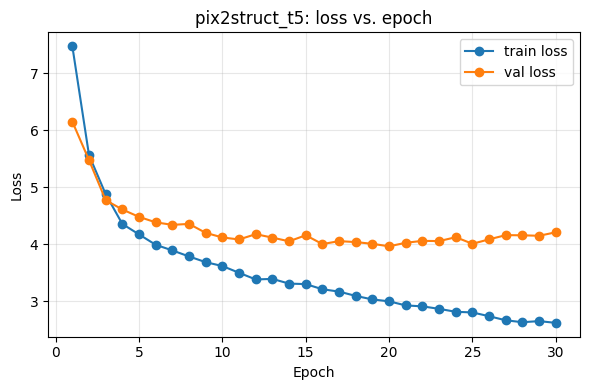

In [34]:
t5_tokenizer = AutoTokenizer.from_pretrained(CONFIG["t5_name"])

pix2struct_t5 = ChartTableGeneratorV2(encoder_type="pix2struct")
result_pix2struct_t5 = train_model_v2(
    pix2struct_t5, t5_tokenizer, df_train_final, df_val_internal,
    tag="pix2struct_t5", encoder_type="pix2struct", batch_size=CONFIG["batch_size_pix2struct"],
)

Loading weights:   0%|          | 0/131 [00:00<?, ?it/s]

[donut_t5] trainable params: 61,032,448  frozen params: 74,180,728
[donut_t5] epoch 1/30  train_loss=5.8755  val_loss=4.8282  (25.0s)
[donut_t5] epoch 2/30  train_loss=4.3860  val_loss=4.5471  (25.0s)
[donut_t5] epoch 3/30  train_loss=4.0098  val_loss=4.2852  (24.9s)
[donut_t5] epoch 4/30  train_loss=3.7780  val_loss=4.3050  (24.9s)
[donut_t5] epoch 5/30  train_loss=3.5778  val_loss=4.1918  (25.0s)
[donut_t5] epoch 6/30  train_loss=3.4575  val_loss=4.1953  (25.0s)
[donut_t5] epoch 7/30  train_loss=3.3486  val_loss=4.0769  (25.0s)
[donut_t5] epoch 8/30  train_loss=3.1507  val_loss=4.0689  (24.9s)
[donut_t5] epoch 9/30  train_loss=3.0429  val_loss=3.9552  (25.0s)
[donut_t5] epoch 10/30  train_loss=2.9565  val_loss=4.0535  (24.9s)
[donut_t5] epoch 11/30  train_loss=2.8544  val_loss=4.1578  (24.9s)
[donut_t5] epoch 12/30  train_loss=2.7270  val_loss=4.1863  (24.9s)
[donut_t5] epoch 13/30  train_loss=2.6288  val_loss=4.0996  (24.9s)
[donut_t5] epoch 14/30  train_loss=2.5664  val_loss=4.1393

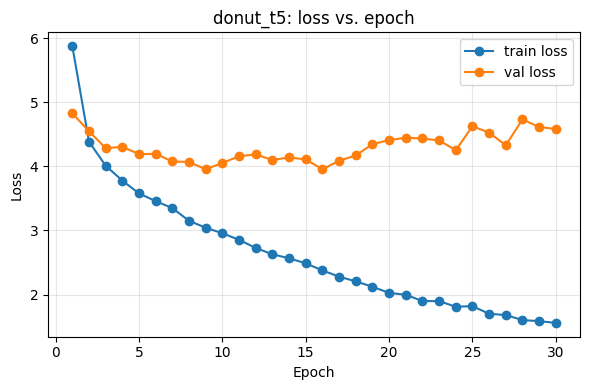

In [35]:
donut_t5 = ChartTableGeneratorV2(encoder_type="donut")
result_donut_t5 = train_model_v2(
    donut_t5, t5_tokenizer, df_train_final, df_val_internal,
    tag="donut_t5", encoder_type="donut", batch_size=CONFIG["batch_size_donut"],
)

## Step 5 — Compare: does the choice of document-pretrained encoder matter?

In [36]:
summary_pix2struct = evaluate_architecture_v2(pix2struct_t5, t5_tokenizer, df_test, "pix2struct", tag="pix2struct_t5")
summary_donut      = evaluate_architecture_v2(donut_t5,      t5_tokenizer, df_test, "donut",      tag="donut_t5")

encoder_comparison = pd.DataFrame([
    {**summary_pix2struct, "trainable_params": result_pix2struct_t5["trainable_params"],
     "frozen_params": result_pix2struct_t5["frozen_params"], "final_val_loss": result_pix2struct_t5["final_val_loss"]},
    {**summary_donut, "trainable_params": result_donut_t5["trainable_params"],
     "frozen_params": result_donut_t5["frozen_params"], "final_val_loss": result_donut_t5["final_val_loss"]},
])
encoder_comparison.to_csv(os.path.join(CONFIG["out_dir"], "encoder_ablation_comparison.csv"), index=False)
print(encoder_comparison.to_string(index=False))

          tag  mean_overall_cell_acc  mean_mined_cell_acc  mean_unmined_cell_acc  relaxed_qa_accuracy  n_charts_evaluated  trainable_params  frozen_params  final_val_loss
pix2struct_t5                    0.0                  NaN                    0.0             0.013208                1166          60901376       91835904        4.210972
     donut_t5                    0.0                  NaN                    0.0             0.003774                1166          61032448       74180728        4.583821


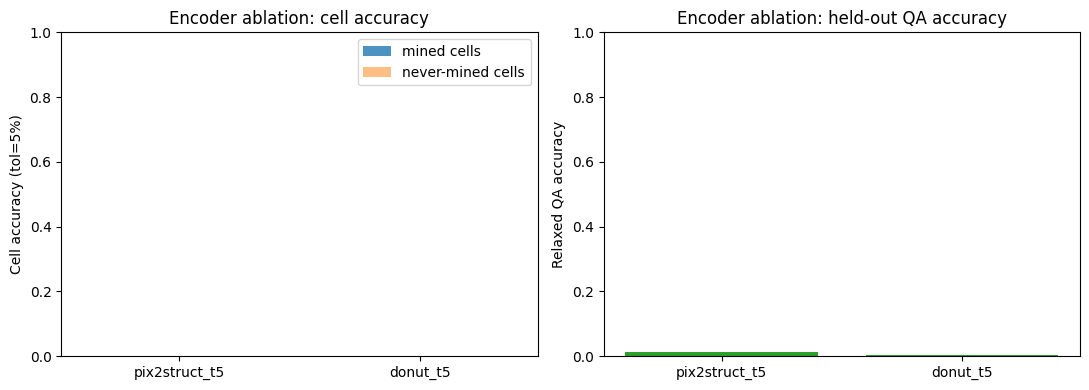

In [37]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].bar(encoder_comparison["tag"], encoder_comparison["mean_mined_cell_acc"].fillna(0), label="mined cells", alpha=0.8)
axes[0].bar(encoder_comparison["tag"], encoder_comparison["mean_unmined_cell_acc"].fillna(0), label="never-mined cells", alpha=0.5)
axes[0].set_ylabel("Cell accuracy (tol=5%)"); axes[0].set_title("Encoder ablation: cell accuracy")
axes[0].legend(); axes[0].set_ylim(0, 1)

axes[1].bar(encoder_comparison["tag"], encoder_comparison["relaxed_qa_accuracy"].fillna(0), color="tab:green")
axes[1].set_ylabel("Relaxed QA accuracy"); axes[1].set_title("Encoder ablation: held-out QA accuracy")
axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.savefig(os.path.join(CONFIG["out_dir"], "encoder_ablation_comparison.png"), dpi=150)
plt.show()

In [38]:
report = {
    "config": CONFIG,
    "data_stats": {
        "train_total_qa_pairs": len(df_train),
        "train_mined_qa_pairs": int(sum(mined_flags_train)),
        "train_usable_charts": len(usable_charts),
    },
    "decoder_held_fixed": CONFIG["t5_name"],
    "experiments": {
        "pix2struct_t5": {k: v for k, v in result_pix2struct_t5.items() if k != "history"},
        "donut_t5":      {k: v for k, v in result_donut_t5.items() if k != "history"},
    },
    "evaluation": {
        "pix2struct_t5": summary_pix2struct,
        "donut_t5": summary_donut,
    },
}
with open(os.path.join(CONFIG["out_dir"], "experiment_report.json"), "w") as f:
    json.dump(report, f, indent=2, default=str)
print("Saved:", os.path.join(CONFIG["out_dir"], "experiment_report.json"))

Saved: /kaggle/working/experiments_encoder_ablation/experiment_report.json


## Step 6 — Qualitative examples (predicted vs. gold table, side by side)

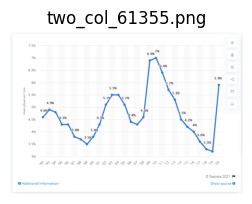

[pix2struct_t5] PREDICTED: {'the number of employees': 5.0}
[pix2struct_t5] GOLD:      {"'20": 5.9, "'19": 3.2, "'18": 3.3, "'17": 3.6, "'16": 4.0, "'15": 4.2, "'14": 4.5, "'13": 5.3, "'12": 5.7, "'11": 6.4, "'10": 7.0, "'09": 6.9, "'08": 4.6, "'07": 4.3, "'06": 4.4, "'05": 5.1, "'04": 5.5, "'03": 5.5, "'02": 5.1, "'01": 4.3, "'00": 3.8, "'99": 3.5, "'98": 3.7, "'97": 3.8, "'96": 4.3, "'95": 4.3, "'94": 4.8, "'93": 4.9, "'92": 4.6}
--------------------------------------------------------------------------------


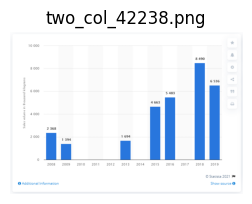

[pix2struct_t5] PREDICTED: {'the number of smartphone users': 78.0}
[pix2struct_t5] GOLD:      {'2019': 6536.0, '2018': 8490.0, '2016': 5483.0, '2015': 4663.0, '2013': 1694.0, '2009': 1394.0, '2008': 2368.0}
--------------------------------------------------------------------------------


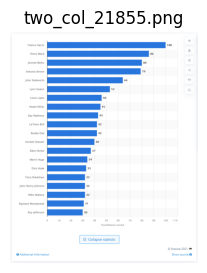

[pix2struct_t5] PREDICTED: {'the total number of employees': 57.0}
[pix2struct_t5] GOLD:      {'Franco Harris': 100.0, 'Hines Ward': 86.0, 'Jerome Bettis': 80.0, 'Antonio Brown': 79.0, 'John Stallworth': 64.0, 'Lynn Swann': 53.0, 'Louis Lipps': 46.0, 'Heath Miller': 45.0, 'Ray Mathews': 43.0, "Le'Veon Bell": 42.0, 'Buddy Dial': 42.0, 'Kordell Stewart': 40.0, 'Elbie Nickel': 37.0, 'Merril Hoge': 34.0, 'Dick Hoak': 33.0, 'Terry Bradshaw': 32.0, 'John Henry Johnson': 32.0, 'Mike Wallace': 32.0, 'Rashard Mendenhall': 31.0, 'Roy Jefferson': 30.0}
--------------------------------------------------------------------------------


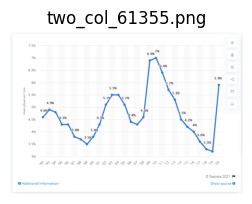

[donut_t5] PREDICTED: {'the forecast for the forecast': 9.4}
[donut_t5] GOLD:      {"'20": 5.9, "'19": 3.2, "'18": 3.3, "'17": 3.6, "'16": 4.0, "'15": 4.2, "'14": 4.5, "'13": 5.3, "'12": 5.7, "'11": 6.4, "'10": 7.0, "'09": 6.9, "'08": 4.6, "'07": 4.3, "'06": 4.4, "'05": 5.1, "'04": 5.5, "'03": 5.5, "'02": 5.1, "'01": 4.3, "'00": 3.8, "'99": 3.5, "'98": 3.7, "'97": 3.8, "'96": 4.3, "'95": 4.3, "'94": 4.8, "'93": 4.9, "'92": 4.6}
--------------------------------------------------------------------------------


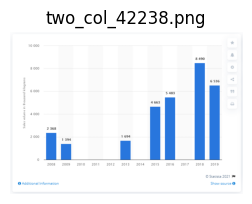

[donut_t5] PREDICTED: {'the estimated number of employees': 49.0}
[donut_t5] GOLD:      {'2019': 6536.0, '2018': 8490.0, '2016': 5483.0, '2015': 4663.0, '2013': 1694.0, '2009': 1394.0, '2008': 2368.0}
--------------------------------------------------------------------------------


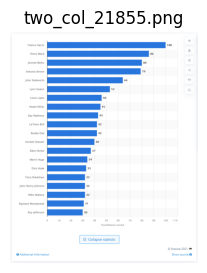

[donut_t5] PREDICTED: {'What was Sergio Busquequequequequequequequequequequequequequequequequequequequequequequequequequequequequeque': 4119.0}
[donut_t5] GOLD:      {'Franco Harris': 100.0, 'Hines Ward': 86.0, 'Jerome Bettis': 80.0, 'Antonio Brown': 79.0, 'John Stallworth': 64.0, 'Lynn Swann': 53.0, 'Louis Lipps': 46.0, 'Heath Miller': 45.0, 'Ray Mathews': 43.0, "Le'Veon Bell": 42.0, 'Buddy Dial': 42.0, 'Kordell Stewart': 40.0, 'Elbie Nickel': 37.0, 'Merril Hoge': 34.0, 'Dick Hoak': 33.0, 'Terry Bradshaw': 32.0, 'John Henry Johnson': 32.0, 'Mike Wallace': 32.0, 'Rashard Mendenhall': 31.0, 'Roy Jefferson': 30.0}
--------------------------------------------------------------------------------


In [39]:
def show_qualitative(model, tokenizer, df_eval, encoder_type, n=3, tag=""):
    sample = df_eval.drop_duplicates("image_path").sample(n=min(n, len(df_eval)), random_state=SEED)
    for _, row in sample.iterrows():
        gold_table = load_gold_table(row["table_path"]) or {}
        image = Image.open(row["image_path"]).convert("RGB")
        inputs = {k: v.to(DEVICE) for k, v in encode_single_image(image, encoder_type).items()}
        out_ids = model.generate(max_new_tokens=CONFIG["max_target_len"], num_beams=2, **inputs)
        pred_table = delinearize_table(tokenizer.decode(out_ids[0], skip_special_tokens=True))

        fig, ax = plt.subplots(figsize=(3, 3))
        ax.imshow(image); ax.axis("off"); ax.set_title(os.path.basename(row["image_path"]))
        plt.show()
        print(f"[{tag}] PREDICTED:", pred_table)
        print(f"[{tag}] GOLD:     ", gold_table)
        print("-" * 80)

show_qualitative(pix2struct_t5, t5_tokenizer, df_test, "pix2struct", n=3, tag="pix2struct_t5")
show_qualitative(donut_t5,      t5_tokenizer, df_test, "donut",      n=3, tag="donut_t5")

## Step 7 — Inference: try your own chart image

Give it any chart image path and pick which encoder to run it through.

In [2]:
def predict_table(image_path = "/kaggle/input/datasets/harshk1111/chartqa-dataset/ChartQA-Dataset/val/png/00006834003066.png", encoder_type="pix2struct"):
    model = pix2struct_t5 if encoder_type == "pix2struct" else donut_t5
    model.eval()
    image = Image.open(image_path).convert("RGB")
    inputs = {k: v.to(DEVICE) for k, v in encode_single_image(image, encoder_type).items()}
    out_ids = model.generate(max_new_tokens=CONFIG["max_target_len"], num_beams=4, **inputs)
    text = t5_tokenizer.decode(out_ids[0], skip_special_tokens=True)
    table = delinearize_table(text)

    fig, ax = plt.subplots(figsize=(4, 4))
    ax.imshow(image); ax.axis("off"); ax.set_title(f"Input chart -> {encoder_type} encoder")
    plt.show()

    print("Raw generated text:", text)
    return pd.DataFrame(list(table.items()), columns=["category", "predicted_value"])

# Example usage (replace with any chart image path):
# predict_table("/kaggle/working/my_new_chart.png", encoder_type="pix2struct")
# predict_table("/kaggle/working/my_new_chart.png", encoder_type="donut")

In [3]:
predict_table(image_path="/kaggle/input/datasets/harshk1111/chartqa-dataset/ChartQA-Dataset/val/png/00484591006451.png", encoder_type="pix2struct")

NameError: name 'pix2struct_t5' is not defined

## Where everything is saved

```
/kaggle/working/experiments_encoder_ablation/
  pix2struct_t5/
    loss_history.csv
    loss_curve.png
    sample_generations.json
    trainable_weights.pt
  donut_t5/
    (same files)
  encoder_ablation_comparison.csv
  encoder_ablation_comparison.png
  experiment_report.json
```

This is completely independent from the T5-vs-BART notebook's `experiments/` folder — the two
notebooks' outputs never collide, so you can keep both as separate, clean experiment records.

In [50]:
import shutil
from IPython.display import FileLink, display

shutil.make_archive(
    "/kaggle/working/experiments_encoder_ablation",
    "zip",
    "/kaggle/working/experiments_encoder_ablation"
)

display(FileLink("/kaggle/working/experiments_encoder_ablation.zip"))

/kaggle/working/experiments_encoder_ablation.zip

In [51]:
import os
import shutil
from IPython.display import FileLink, display

folder = "/kaggle/working/experiments_encoder_ablation"
zip_path = "/kaggle/working/experiments_encoder_ablation.zip"

# Create ZIP containing both donut_t5 and pix2struct_t5
if os.path.exists(zip_path):
    os.remove(zip_path)

shutil.make_archive(folder, "zip", folder)

print("ZIP exists:", os.path.exists(zip_path))
print("ZIP size:", round(os.path.getsize(zip_path) / (1024**2), 2), "MB")

# Display a clickable download link
display(FileLink("experiments_encoder_ablation.zip"))

ZIP exists: True
ZIP size: 363.87 MB


/kaggle/working/experiments_encoder_ablation.zip